In [3]:
# 1. Install dependencies
# ultralytics wraps SAM2 with a very simple API — no need to clone Meta's repo
%pip install -q ultralytics opencv-python matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import SAM

# Load SAM2 (small/base checkpoint — downloads automatically on first run)
sam_model = SAM("sam2_b.pt")
print(sam_model.info())

WARNING Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\medha\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Model summary: 436 layers, 80,833,666 parameters, 80,833,666 gradients
(436, 80833666, 80833666, 0.0)


In [10]:
# 3. Point this at your images folder
IMAGE_DIR = Path("images")   # change if your folder is named differently
OUTPUT_DIR = Path("annotations_output")
(OUTPUT_DIR / "masks").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "overlays").mkdir(parents=True, exist_ok=True)

object_folders = [p for p in IMAGE_DIR.iterdir() if p.is_dir()]
print("Found object folders:", [p.name for p in object_folders])

Found object folders: ['book', 'bottle', 'duster', 'plushie']


In [ ]:
E_LOOKUP = {
    "book":     2.0,     # paperback, stacked paper/cardstock
    "bottle":   193.0,   # assuming stainless steel — check base stamp, drop to ~70 if aluminum
    "duster":   0.05,    # felt/foam pad dominates contact
    "plushie":  0.005,   # soft fabric + stuffing, no rigid core
}
# sanity check every folder has a matching E value
for folder in object_folders:
    if folder.name not in E_LOOKUP:
        print(f"WARNING: no E value set for '{folder.name}' — add it to E_LOOKUP above")

In [12]:
# 5. Core function: run SAM on one image with a center-point prompt
# (single object roughly centered on a plain surface, per the collection protocol)

def segment_object(image_path):
    img = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    center_point = [[w // 2, h // 2]]

    results = sam_model(img_rgb, points=center_point, labels=[1], verbose=False)
    mask = results[0].masks.data[0].cpu().numpy()  # (H, W) boolean-ish mask
    mask = (mask > 0.5).astype(np.uint8)
    return img_rgb, mask

In [13]:
# 6. Run over every image, save mask + overlay, build annotation rows

rows = []

for folder in object_folders:
    obj_name = folder.name
    e_val = E_LOOKUP.get(obj_name)
    if e_val is None:
        continue
    log_e = float(np.log(e_val))

    images = sorted([p for p in folder.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png")])
    print(f"{obj_name}: {len(images)} images")

    for img_path in images:
        img_rgb, mask = segment_object(img_path)

        mask_filename = OUTPUT_DIR / "masks" / f"{obj_name}_{img_path.stem}_mask.png"
        cv2.imwrite(str(mask_filename), mask * 255)

        # quick overlay for visual sanity-checking
        overlay = img_rgb.copy()
        overlay[mask.astype(bool)] = (0.5 * overlay[mask.astype(bool)] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
        overlay_filename = OUTPUT_DIR / "overlays" / f"{obj_name}_{img_path.stem}_overlay.png"
        cv2.imwrite(str(overlay_filename), cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))

        rows.append({
            "image_path": str(img_path),
            "object": obj_name,
            "e_gpa": e_val,
            "log_e": log_e,
            "mask_path": str(mask_filename),
            "mask_area_px": int(mask.sum()),
        })

annotations = pd.DataFrame(rows)
annotations.to_csv(OUTPUT_DIR / "annotations.csv", index=False)
print(f"\nSaved {len(annotations)} annotated images to {OUTPUT_DIR/'annotations.csv'}")
annotations.head(10)

book: 6 images
bottle: 8 images
duster: 7 images
plushie: 8 images

Saved 29 annotated images to annotations_output\annotations.csv


,image_path,object,e_gpa,log_e,mask_path,mask_area_px
0,images\book\IMG_6313.jpg,book,2.0,0.693147,annotations_output\masks\book_IMG_6313_mask.png,6967860
1,images\book\IMG_6314.jpg,book,2.0,0.693147,annotations_output\masks\book_IMG_6314_mask.png,757062
2,images\book\IMG_6315.jpg,book,2.0,0.693147,annotations_output\masks\book_IMG_6315_mask.png,10100597
3,images\book\IMG_6316.jpg,book,2.0,0.693147,annotations_output\masks\book_IMG_6316_mask.png,13090451
4,images\book\IMG_6317.jpg,book,2.0,0.693147,annotations_output\masks\book_IMG_6317_mask.png,8561922
5,images\book\IMG_6319.jpg,book,2.0,0.693147,annotations_output\masks\book_IMG_6319_mask.png,11400866
6,images\bottle\IMG_6303.jpg,bottle,193.0,5.262690,annotations_output\masks\bottle_IMG_6303_mask.png,4111788
7,images\bottle\IMG_6304.jpg,bottle,193.0,5.262690,annotations_output\masks\bottle_IMG_6304_mask.png,4136015
8,images\bottle\IMG_6305.jpg,bottle,193.0,5.262690,annotations_output\masks\bottle_IMG_6305_mask.png,5093635
9,images\bottle\IMG_6306.jpg,bottle,193.0,5.262690,annotations_output\masks\bottle_IMG_6306_mask.png,3969638


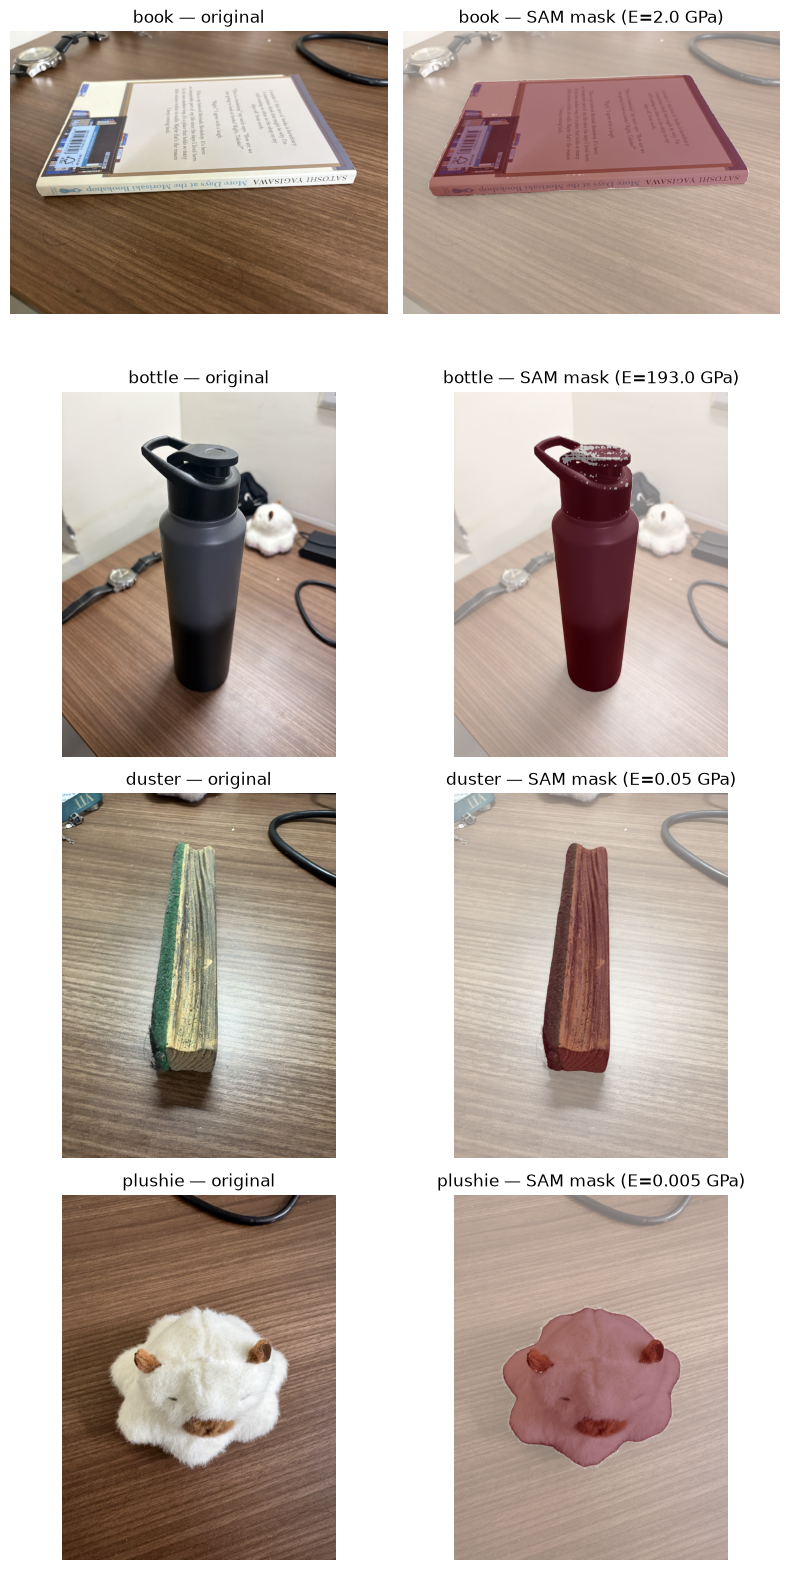

In [14]:
# 7. Visual sanity check — one example per object, image + mask overlay side by side

fig, axes = plt.subplots(len(object_folders), 2, figsize=(8, 4 * len(object_folders)))
if len(object_folders) == 1:
    axes = axes.reshape(1, -1)

for i, folder in enumerate(object_folders):
    obj_name = folder.name
    sub = annotations[annotations["object"] == obj_name]
    if sub.empty:
        continue
    row = sub.iloc[0]
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{obj_name} — original")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(img)
    axes[i, 1].imshow(mask, alpha=0.5, cmap="Reds")
    axes[i, 1].set_title(f"{obj_name} — SAM mask (E={row['e_gpa']} GPa)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pilot_summary_grid.png", dpi=150)
plt.show()